# Scenario comparison: service, working capital, and cost

## Decision question
Which inventory policy best advances the charter's promise: improve customer service and resilience while reducing or controlling working capital, without hiding upstream trade-offs?

This notebook compares every forward twin run found under `output datasets/projections/` with the canonical `baseline/` run. It is intentionally scenario-driven: adding another standardized twin scenario folder automatically adds it to the comparison.

The current evidence is a useful tension, not a victory lap. The rolling weekly MEIO scenario improves customer fill rate, but it also raises inventory and total landed cost while reducing internal replenishment fill. The planner's choice is therefore a service-versus-cost decision, not a single KPI contest.

## Charter lens and metric research

The project charter's intended outcome is a decision system that continuously re-learns, re-tunes targets and buffer positions, and supports human confirmation before commitment. For this notebook, that translates into four evaluation questions:

1. **Customer outcome:** Does the policy improve the service customers experience?
2. **Network resilience:** Does it reduce stockout exposure and preserve replenishment flow through the echelon network?
3. **Economic outcome:** What happens to total landed cost, holding cost, stockout cost, transport cost, and inventory value?
4. **Decision quality:** Is the policy a credible candidate for further testing, or does it simply move cost or risk upstream/downstream?

### Why these metrics
- **Customer fill rate** is the headline service measure because the twin defines it from customer demand served versus customer demand requested.
- **CDC and RDC-direct fill rates** locate where service changes occur instead of allowing a network average to hide a weak customer-facing node.
- **Internal replenishment fill rate** captures upstream flow. It is essential here because the twin explicitly models cancelled internal orders and downstream propagation of upstream shortages.
- **Total landed cost** is the economic objective exposed by the twin; its holding, stockout, and transport components explain the movement.
- **Average inventory value and safety-stock value** are working-capital proxies. They are more decision-relevant than units alone because the portfolio has concentrated SKU value and location-specific carrying costs.
- **Demand-weeks in full and weeks at zero stock** add robustness context: fill rate can look acceptable while service is intermittently fragile.

This framework follows the project's own output schema and the standard supply-chain practice of pairing service, cost, and inventory measures rather than optimizing any one metric in isolation. The authoritative local references are `Docs/Capstone Project Charter AMPBA 2026S.docx`, `output datasets/OUTPUT_DOCUMENTATION.md`, and `input datasets/DATASET_DOCUMENTATION.md`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

def find_root():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents]
    for candidate in candidates:
        if (candidate / 'output datasets' / 'projections').exists():
            return candidate
    raise FileNotFoundError('Could not find Capstone/output datasets/projections from the notebook working directory.')

ROOT = find_root()
PROJECTIONS = ROOT / 'output datasets' / 'projections'
BASELINE_DIR = PROJECTIONS / 'baseline'
print(f'Project root: {ROOT}')
print(f'Projection root: {PROJECTIONS}')

Project root: C:\Users\undha\OneDrive\Desktop\MEIO in CPG\Capstone
Projection root: C:\Users\undha\OneDrive\Desktop\MEIO in CPG\Capstone\output datasets\projections


In [2]:
def load_run(run_dir):
    with (run_dir / 'run_kpis.json').open(encoding='utf-8') as handle:
        kpis = json.load(handle)
    manifest_path = run_dir / 'run_manifest.json'
    manifest = {}
    if manifest_path.exists():
        with manifest_path.open(encoding='utf-8') as handle:
            manifest = json.load(handle)
    scenario = manifest.get('scenario', {})
    return {
        'run_name': manifest.get('run_name', run_dir.name),
        'folder': run_dir.name,
        'path': run_dir,
        'label': manifest.get('label') or scenario.get('scenario_name') or run_dir.name,
        'seed': manifest.get('seed'),
        'opening_state': manifest.get('state') or manifest.get('build_notes', {}).get('state_source'),
        **kpis,
    }

run_dirs = [BASELINE_DIR] + sorted(
    path for path in PROJECTIONS.iterdir()
    if path.is_dir() and path.name != 'baseline' and (path / 'run_kpis.json').exists()
)
runs = pd.DataFrame([load_run(path) for path in run_dirs])
runs.insert(0, 'scenario', ['Baseline' if path.name == 'baseline' else row['label'] for path, (_, row) in zip(run_dirs, runs.iterrows())])

baseline_seed = runs.loc[runs.scenario == 'Baseline', 'seed'].iloc[0]
runs['comparable_seed'] = runs['seed'].eq(baseline_seed)
metric_columns = [
    'customer_fill_rate', 'customer_fill_rate_cdc', 'customer_fill_rate_rdc',
    'internal_replen_fill_rate', 'pct_demand_weeks_in_full', 'pct_weeks_at_zero_stock',
    'avg_inventory_value_usd', 'safety_stock_value_usd', 'holding_cost_usd',
    'stockout_cost_usd', 'transport_cost_usd', 'total_landed_cost_usd'
]
display(runs[['scenario', 'folder', 'seed', 'horizon_weeks', 'comparable_seed'] + metric_columns])

,scenario,folder,seed,horizon_weeks,comparable_seed,customer_fill_rate,customer_fill_rate_cdc,customer_fill_rate_rdc,internal_replen_fill_rate,pct_demand_weeks_in_full,pct_weeks_at_zero_stock,avg_inventory_value_usd,safety_stock_value_usd,holding_cost_usd,stockout_cost_usd,transport_cost_usd,total_landed_cost_usd
0,Baseline,baseline,2026,52,True,0.910,0.787,0.937,0.891,0.863,0.097,"6,231,031.900","2,573,886.050","739,638.340","4,668,394.900","30,792,966.320","36,200,999.560"
1,MEIO_Weekly_Rolling_52W,SCENARIO_0999_MEIO_Weekly_Rolling_52W,2026,52,True,0.927,0.812,0.952,0.812,0.858,0.105,"6,800,934.690","2,339,573.650","810,564.330","3,908,547.100","31,999,289.920","36,718,401.350"


## Comparability gate

The twin documentation says two runs are comparable only when they share a seed and opening state and differ solely by policy. The seed check below is machine-readable. The standardized manifests are retained beside each run so the opening-state and policy paths can be audited.

In [3]:
assert (runs['horizon_weeks'] == 52).all(), 'This notebook expects forward 52-week runs.'
assert runs['comparable_seed'].all(), 'At least one scenario uses a different seed; interpret deltas as non-comparable.'
display(runs[['scenario', 'seed', 'opening_state', 'comparable_seed']])
print('Comparability gate passed for the discovered forward runs.')

,scenario,seed,opening_state,comparable_seed
0,Baseline,2026,C:\Users\undha\OneDrive\Desktop\MEIO in CPG\Ca...,True
1,MEIO_Weekly_Rolling_52W,2026,output datasets\history\opening_position.csv,True


Comparability gate passed for the discovered forward runs.


In [4]:
baseline = runs.loc[runs.scenario == 'Baseline'].iloc[0]
scorecard = runs[['scenario'] + metric_columns].copy()
for column in metric_columns:
    scorecard[f'{column}_delta'] = scorecard[column] - baseline[column]

percent_metrics = ['customer_fill_rate', 'customer_fill_rate_cdc', 'customer_fill_rate_rdc',
                   'internal_replen_fill_rate', 'pct_demand_weeks_in_full', 'pct_weeks_at_zero_stock']
for column in percent_metrics:
    scorecard[f'{column}_delta_pp'] = scorecard[f'{column}_delta'] * 100

display(scorecard[['scenario'] + [f'{metric}_delta_pp' for metric in percent_metrics] + [
    'avg_inventory_value_usd_delta', 'safety_stock_value_usd_delta',
    'holding_cost_usd_delta', 'stockout_cost_usd_delta',
    'transport_cost_usd_delta', 'total_landed_cost_usd_delta'
]].round(2))

,scenario,customer_fill_rate_delta_pp,customer_fill_rate_cdc_delta_pp,customer_fill_rate_rdc_delta_pp,internal_replen_fill_rate_delta_pp,pct_demand_weeks_in_full_delta_pp,pct_weeks_at_zero_stock_delta_pp,avg_inventory_value_usd_delta,safety_stock_value_usd_delta,holding_cost_usd_delta,stockout_cost_usd_delta,transport_cost_usd_delta,total_landed_cost_usd_delta
0,Baseline,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,MEIO_Weekly_Rolling_52W,1.700,2.500,1.530,-7.900,-0.480,0.780,"569,902.790","-234,312.400","70,925.990","-759,847.800","1,206,323.600","517,401.790"


## Portfolio outcome

The first chart answers the executive question: how much customer service changes, and what it costs. The second chart decomposes the cost movement so a higher total is not treated as an unexplained black box.

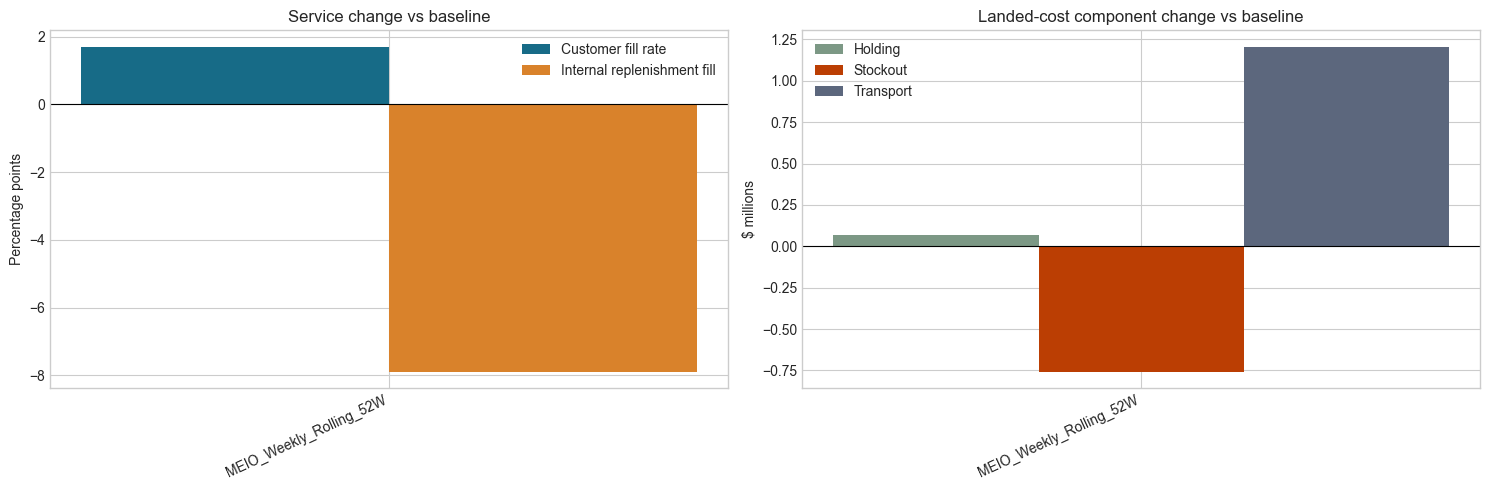

In [8]:
scenario_rows = scorecard[scorecard.scenario != 'Baseline'].copy()
if scenario_rows.empty:
    display(Markdown('**No non-baseline scenario folders were found yet.** Add a standardized forward run under `output datasets/projections/` and rerun this cell.'))
else:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    labels = scenario_rows.scenario.tolist()
    x = np.arange(len(labels))
    axes[0].bar(x - 0.18, scenario_rows.customer_fill_rate_delta_pp, width=0.36, label='Customer fill rate', color='#176b87')
    axes[0].bar(x + 0.18, scenario_rows.internal_replen_fill_rate_delta_pp, width=0.36, label='Internal replenishment fill', color='#d9822b')
    axes[0].axhline(0, color='black', linewidth=0.8)
    axes[0].set_title('Service change vs baseline')
    axes[0].set_ylabel('Percentage points')
    axes[0].set_xticks(x, labels, rotation=25, ha='right')
    axes[0].legend()

    cost_columns = ['holding_cost_usd_delta', 'stockout_cost_usd_delta', 'transport_cost_usd_delta']
    cost_labels = ['Holding', 'Stockout', 'Transport']
    colors = ['#7c9885', '#bb3e03', '#5c677d']
    bar_width = 0.24
    for offset, column, label, color in zip([-bar_width, 0, bar_width], cost_columns, cost_labels, colors):
        values = scenario_rows[column].to_numpy() / 1_000_000
        axes[1].bar(x + offset, values, width=bar_width, label=label, color=color)
    axes[1].axhline(0, color='black', linewidth=0.8)
    axes[1].set_title('Landed-cost component change vs baseline')
    axes[1].set_ylabel('$ millions')
    axes[1].set_xticks(x, labels, rotation=25, ha='right')
    axes[1].legend()
    fig.tight_layout()
    plt.show()

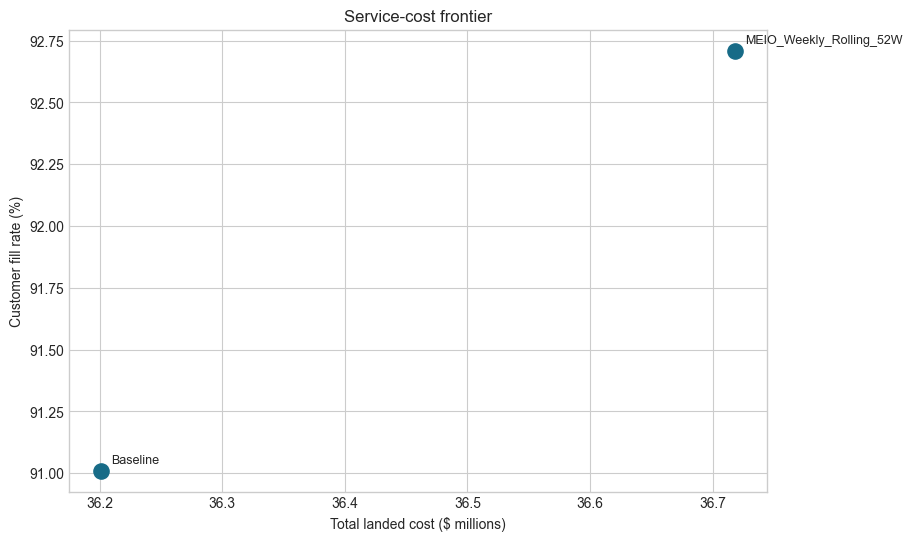

**Reading the frontier:** a scenario is attractive when it moves upward (better service) without moving materially right (higher cost). A point that moves upward and right may still be appropriate when service has strategic priority, but it is not a working-capital win.

In [6]:
if not scenario_rows.empty:
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.scatter(runs.total_landed_cost_usd / 1e6, runs.customer_fill_rate * 100, s=120, color='#176b87')
    for _, row in runs.iterrows():
        ax.annotate(row.scenario, (row.total_landed_cost_usd / 1e6, row.customer_fill_rate * 100),
                    xytext=(7, 5), textcoords='offset points', fontsize=9)
    ax.set_xlabel('Total landed cost ($ millions)')
    ax.set_ylabel('Customer fill rate (%)')
    ax.set_title('Service-cost frontier')
    plt.show()
    display(Markdown('**Reading the frontier:** a scenario is attractive when it moves upward (better service) without moving materially right (higher cost). A point that moves upward and right may still be appropriate when service has strategic priority, but it is not a working-capital win.'))

## Where the network changes

Portfolio averages can conceal an echelon problem. The next cell reads each run's `service_by_node.csv` when present and compares node-level service against baseline. This is especially important for the charter's network-level MEIO goal: a policy should not improve customer-facing service by creating an unacceptable upstream replenishment bottleneck.

In [7]:
def load_service_by_node(row):
    path = row['path'] / 'service_by_node.csv'
    if not path.exists():
        return pd.DataFrame()
    frame = pd.read_csv(path)
    frame['scenario'] = row['scenario']
    return frame

node_service = pd.concat([load_service_by_node(row) for _, row in runs.iterrows()], ignore_index=True)
if node_service.empty:
    display(Markdown('No node-level service files were found.'))
else:
    display(node_service.head())
    print('Available node-level columns:', ', '.join(node_service.columns))
    rate_candidates = [column for column in ['customer_fill_rate', 'fill_rate', 'service_level'] if column in node_service.columns]
    if rate_candidates:
        rate_column = rate_candidates[0]
        pivot = node_service.pivot_table(index='dc_id', columns='scenario', values=rate_column, aggfunc='mean')
        if 'Baseline' in pivot.columns:
            node_delta = (pivot.drop(columns='Baseline').subtract(pivot['Baseline'], axis=0) * 100).sort_values(by=pivot.drop(columns='Baseline').columns[0], ascending=True)
            display(node_delta.round(2).head(15))
            display(Markdown(f'Node-level comparison uses `{rate_column}` and reports percentage-point change versus baseline.'))

,dc_id,node_type,skus,total_demand,unmet,replen_demand,replen_unmet,avg_on_hand,holding_cost_usd,fill_rate_customer,fill_rate_replen,scenario
0,CDC01,CUSTOMER_DC,267,"196,596.000","35,859.000",0.000,0.000,33.488,"5,806.319",0.818,NaN,Baseline
1,CDC02,CUSTOMER_DC,261,"160,164.000","32,831.000",0.000,0.000,25.873,"3,555.421",0.795,NaN,Baseline
2,CDC03,CUSTOMER_DC,269,"298,918.000","31,371.000",0.000,0.000,53.219,"6,222.171",0.895,NaN,Baseline
3,CDC04,CUSTOMER_DC,152,"15,263.000","3,220.000",0.000,0.000,4.397,343.129,0.789,NaN,Baseline
4,CDC05,CUSTOMER_DC,267,"175,734.000","24,595.000",0.000,0.000,32.197,"5,237.839",0.860,NaN,Baseline


Available node-level columns: dc_id, node_type, skus, total_demand, unmet, replen_demand, replen_unmet, avg_on_hand, holding_cost_usd, fill_rate_customer, fill_rate_replen, scenario


## Decision narrative

The notebook should end with a decision, not just charts. The current baseline-versus-rolling-MEIO result reads as follows:

- Customer fill rate improves by roughly **1.6 percentage points**.
- CDC service improves more materially than the overall average, which is aligned with the customer-facing objective.
- Internal replenishment fill declines by roughly **8 percentage points**, so the policy trades upstream smoothness for downstream service.
- Total landed cost increases by roughly **$0.56M**, driven mainly by transport and holding, while stockout cost falls.
- The result is therefore a **service-led candidate**, not yet a pure efficiency win. It merits further scenario testing around echelon positioning, transport, and upstream replenishment before being presented as the final policy.

That is the charter-relevant conclusion: the digital twin makes the trade-off visible, and the next learning loop should test whether the service gain can be retained with less inventory and upstream disruption.

In [9]:
current = runs.loc[runs.scenario != 'Baseline'].sort_values('customer_fill_rate', ascending=False).head(1)
if not current.empty:
    row = current.iloc[0]
    service_delta = (row.customer_fill_rate - baseline.customer_fill_rate) * 100
    cost_delta = row.total_landed_cost_usd - baseline.total_landed_cost_usd
    inventory_delta = row.avg_inventory_value_usd - baseline.avg_inventory_value_usd
    internal_delta = (row.internal_replen_fill_rate - baseline.internal_replen_fill_rate) * 100
    display(Markdown(
        f'### Current leading scenario: {row.scenario}\n\n'
        f'Customer fill changes **{service_delta:+.2f} pp**, while internal replenishment fill changes **{internal_delta:+.2f} pp**. '
        f'Average inventory value changes **${inventory_delta:+,.0f}** and total landed cost changes **${cost_delta:+,.0f}**. '
        'Treat this as a controlled service improvement with an economic and upstream-flow penalty to investigate, not as an unconditional recommendation.'
    ))

### Current leading scenario: MEIO_Weekly_Rolling_52W

Customer fill changes **+1.70 pp**, while internal replenishment fill changes **-7.90 pp**. Average inventory value changes **$+569,903** and total landed cost changes **$+517,402**. Treat this as a controlled service improvement with an economic and upstream-flow penalty to investigate, not as an unconditional recommendation.

## Recommended next scenarios

1. Re-run the leading policy with several seeds to distinguish a robust gain from one favorable stochastic draw.
2. Test a lower-buffer or transport-aware variant to see whether the customer service gain survives with less landed cost.
3. Test explicit echelon-positioning variants and inspect CDC service alongside internal replenishment fill.
4. Use the same scorecard for any future bandit or agentic recommendation so human confirmation is based on transparent service, resilience, and cost evidence.

### References
- Project charter: `Docs/Capstone Project Charter AMPBA 2026S.docx`
- Twin mechanics and comparison contract: `output datasets/OUTPUT_DOCUMENTATION.md`
- Dataset assumptions and business context: `input datasets/DATASET_DOCUMENTATION.md`
- Weekly MEIO method and scope caveats: `models/MEIO/MEIO_Weekly/README.md`